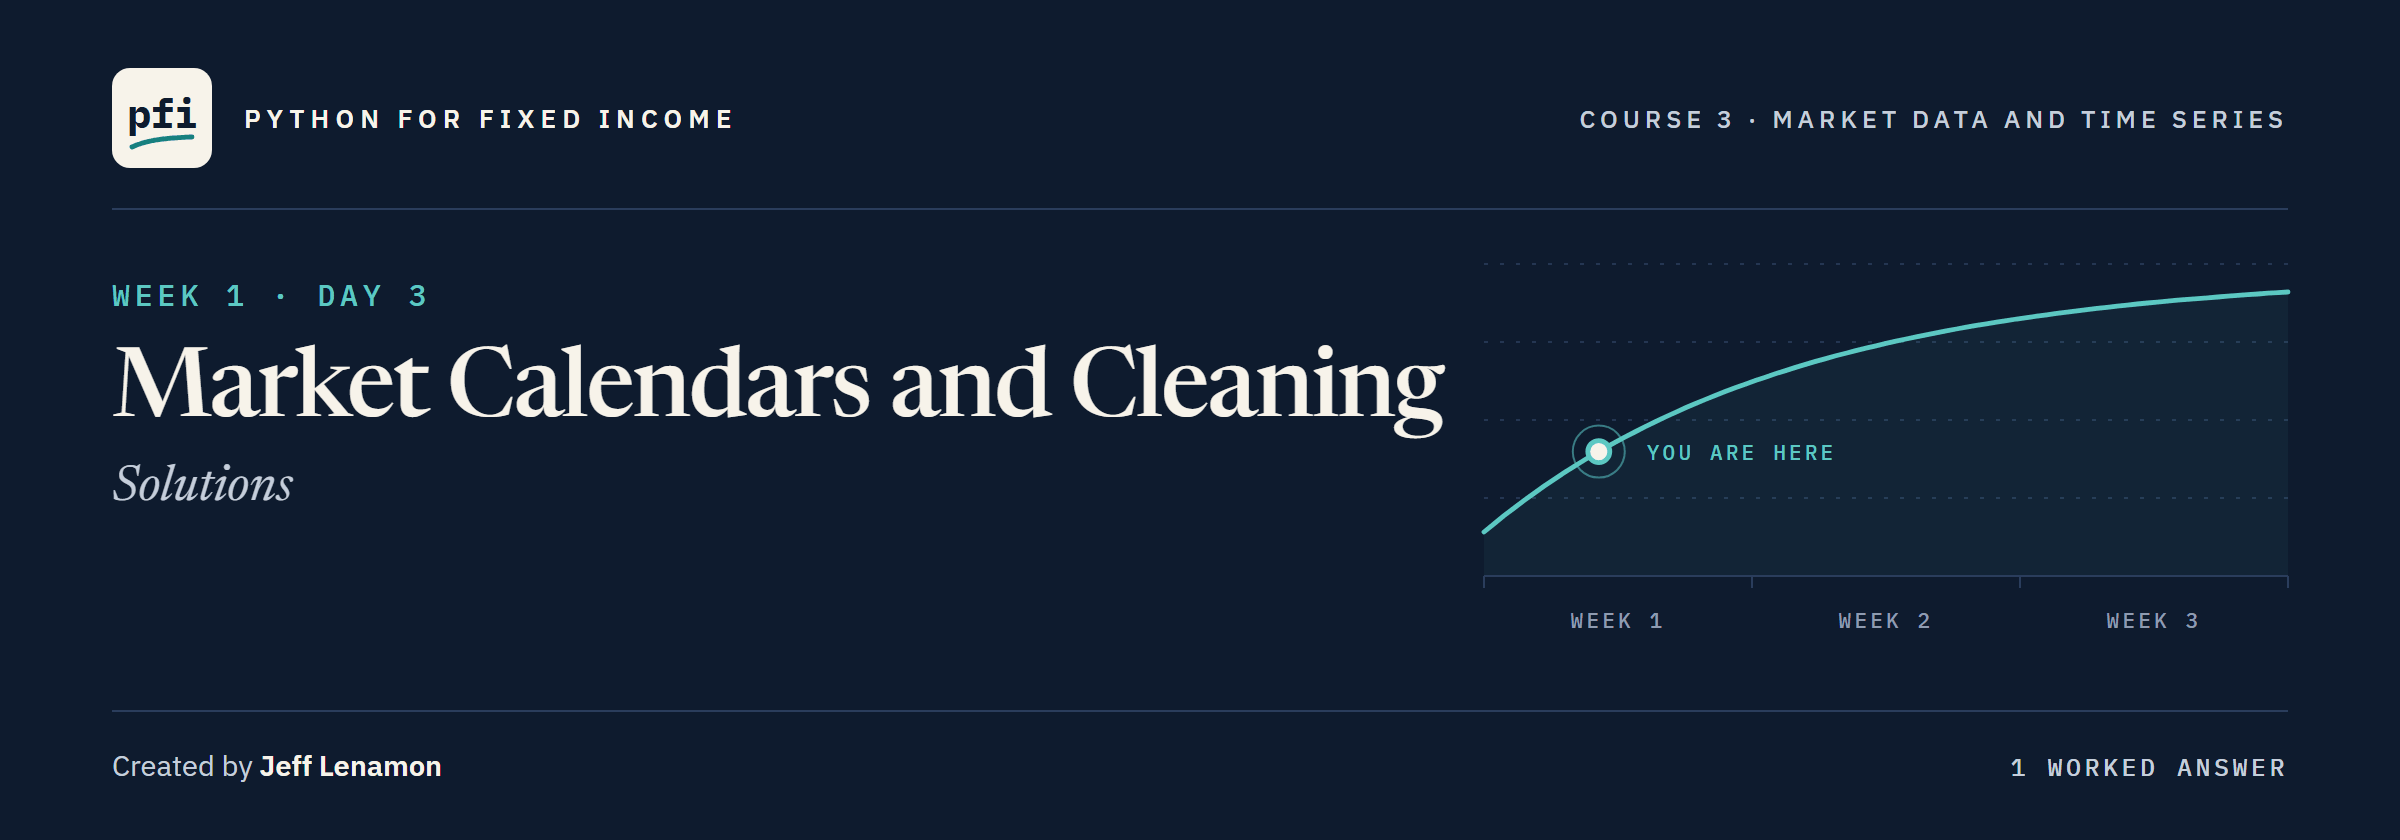

# Market Calendars and Cleaning: Solutions

Week 1, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day3/03_market_calendars_and_cleaning_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the files.

No key is needed.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 03 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(3, after=3)

Work folder pfi_course3_03_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 03 left it, 3 commits


In [2]:
import importlib

import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

import marketdata as md

print('stale_runs is in the module:', 'stale_runs' in dir(md))

stale_runs is in the module: True


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# the two files, the missing weekdays, and pandas' federal holidays
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
missing = md.missing_weekdays(treasury.index)
federal = USFederalHolidayCalendar().holidays(treasury.index[0], treasury.index[-1],
                                              return_name=True)

### Exercise 1

In [5]:
ex1_counts = [int((missing.year == 2020).sum()), int((missing.year == 2025).sum())]
missing_2025 = missing[missing.year == 2025]
ex1_not_federal = list(missing_2025.difference(federal.index).strftime('%Y-%m-%d'))
print(ex1_counts, ex1_not_federal)

[11, 12] ['2025-04-18']


In [6]:
check('Exercise 1 the counts', ex1_counts, [11, 12])
check('Exercise 1 not federal in 2025', ex1_not_federal, ['2025-04-18'])

Exercise 1 the counts: correct
Exercise 1 not federal in 2025: correct


2025's one closure outside the federal list is Good Friday.

### Exercise 2

In [7]:
pair = {'5 Yr': treasury.loc['2026', '5 Yr'], 'hy_spread_bp': spreads['hy_spread_bp']}
ex2_inner_rows = len(md.align(pair))
ex2_outer_missing = md.align(pair, how='outer')['5 Yr'].isna().sum()
print(ex2_inner_rows, 'inner rows;', ex2_outer_missing, 'NaN in the outer 5 Yr')

190 inner rows; 2750 NaN in the outer 5 Yr


In [8]:
check('Exercise 2 inner rows', ex2_inner_rows, 190)
check('Exercise 2 outer NaN', ex2_outer_missing, 2750)

Exercise 2 inner rows: correct
Exercise 2 outer NaN: correct


The outer join keeps every spread date since 2015; the 5 Yr's 2,750 cells before 2026 stay empty, never filled.

### Exercise 3

In [9]:
%%writefile -a marketdata.py


def market_days_between(index: pd.DatetimeIndex, start, end) -> int:
    """The number of market days from start to end, both included.

    Units: a count of rows. Convention: the index is the market calendar, its own dates; start and end
    may be any dates, market days or not. Excel's NETWORKDAYS(start, end, holidays) gives the same count
    when the holidays are the index's missing weekdays.
    Raises ValueError if start is after end, or if the index is not unique ascending dates.
    """
    _check_index(index, "index")
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start > end:
        raise ValueError(f"start {start.date()} is after end {end.date()}")
    # count the rows on or after start and on or before end
    return int(((index >= start) & (index <= end)).sum())

Appending to marketdata.py


In [10]:
%%writefile -a test_marketdata.py


def test_market_days_between_counts_rows():
    # Labor Day, Monday 2026-09-07, has no row, so Friday to Tuesday is two market days
    index = pd.DatetimeIndex(["2026-09-03", "2026-09-04", "2026-09-08", "2026-09-09"])
    assert md.market_days_between(index, "2026-09-04", "2026-09-08") == 2
    # a start or end with no row is fine: those days are simply not counted
    assert md.market_days_between(index, "2026-09-05", "2026-09-07") == 0
    with pytest.raises(ValueError):
        md.market_days_between(index, "2026-09-09", "2026-09-03")

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............                                                           [100%]
14 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_september = md.market_days_between(treasury.index, '2026-09-01', '2026-09-30')
print(ex3_september, 'market days in September 2026')

21 market days in September 2026


In [13]:
check('Exercise 3 market days in September 2026', ex3_september, 21)

Exercise 3 market days in September 2026: correct


21, as Excel's `NETWORKDAYS` with the seven dates as its list.

### Exercise 4: AI check

The bug: the docstring says the data's own dates decide, and the code asks pandas' federal calendar.
So it returns 121 dates, reports the 4 Fridays the file has as closed, and misses 9 closures, Good Friday 2025 among them.
The fix takes the weekdays the index skips, as `missing_weekdays` does.

In [14]:
# written for this course in the style of an AI assistant's answer, now fixed
def closed_days(index):
    """The weekdays from the first date to the last on which the market had no row.

    Units: dates. Convention: the data's own dates are the market calendar. A weekday with a row
    was open, a weekday without one was closed, whatever the reason. No holiday calendar
    decides it.
    """
    # the fix: a closed day is a weekday the index has no row for
    return pd.bdate_range(index[0], index[-1]).difference(index)

In [15]:
# the test, written from the docstring before the code is trusted
closed = closed_days(treasury.index)
assert pd.Timestamp('2025-04-18') in closed, 'a weekday with no row is missing'
assert not closed.isin(treasury.index).any(), 'a day with a row is reported closed'
assert closed.equals(missing), "the result is not the file's own calendar"
print("closed_days is the file's own calendar")

closed_days is the file's own calendar


In [16]:
ex4_count = len(closed_days(treasury.index))
ex4_with_rows = closed_days(treasury.index).isin(treasury.index).sum()
check('Exercise 4 closed days', ex4_count, 126)
check('Exercise 4 closed days with a row', ex4_with_rows, 0)

Exercise 4 closed days: correct
Exercise 4 closed days with a row: correct


Keep the test: in your test file, a holiday library cannot quietly become the calendar again.

[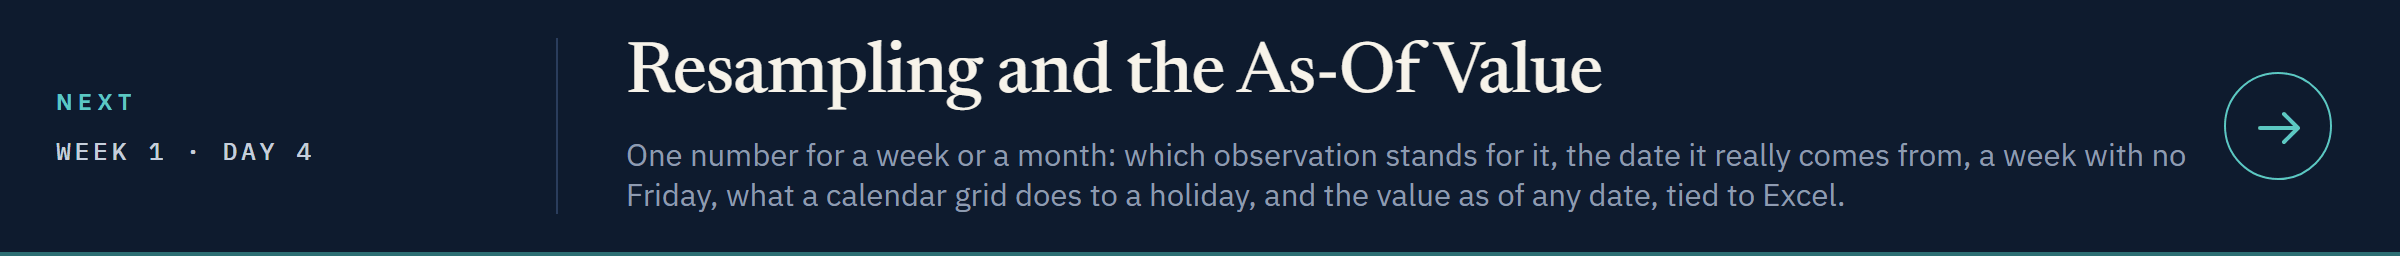](../day4/04_resampling_and_the_as_of_value.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day4/04_resampling_and_the_as_of_value.ipynb)